
# Structured Latent Neural ODE for Images

This notebook presents the **car-at-an-intersection** example, with a structured latent representation.

Instead of asking a generic autoencoder to compress the whole image, we explicitly force the latent state to represent the **car position**:

$$
z = (x, y) \in [0,1]^2.
$$

The key idea is:

1. **Encoder**: a small CNN reads the image and predicts the car center $(x,y)$.
2. **Structured decoder / renderer**: given $(x,y)$, we redraw the car at that location on a known background.
3. **Neural ODE**: we learn a continuous latent dynamics
   $$
   \dot z = f_\theta(z)
  $$
   from sparse temporal observations.
4. **Decoding to images**: once the Neural ODE predicts a full latent trajectory, we map it back to images with the renderer.

This works much better than an unconstrained image autoencoder because the latent is **interpretable** and directly tied to the moving object.


In [ ]:
%pip -q install torchdiffeq


In [ ]:

import math
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchdiffeq import odeint

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)


Using device: cpu



## 1. Synthetic scene: an intersection and a moving car

We create a simple synthetic world:

- a fixed background with a horizontal/vertical road crossing,
- a small red car,
- trajectories where the car moves from left to right.

For clarity, we keep the dynamics simple:

$$
\dot x = v, \qquad \dot y = 0.
$$

Different trajectories have different initial positions and possibly slightly different lane heights, but the motion law is shared.


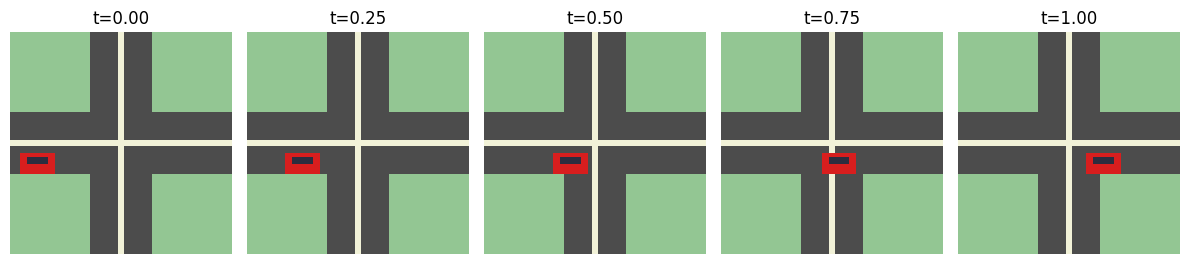

In [ ]:

H = W = 64
CAR_W = 10
CAR_H = 6
T_END = 1.0
SPEED = 0.55  # shared velocity for all trajectories


def make_background(h=H, w=W):
    """Return a simple RGB image of an intersection."""
    img = np.zeros((h, w, 3), dtype=np.float32)
    img[:] = np.array([0.58, 0.78, 0.58], dtype=np.float32)  # grass

    # Horizontal road
    img[h//2-9:h//2+9, :, :] = np.array([0.30, 0.30, 0.30], dtype=np.float32)
    # Vertical road
    img[:, w//2-9:w//2+9, :] = np.array([0.30, 0.30, 0.30], dtype=np.float32)

    # Lane markings
    img[h//2-1:h//2+1, :, :] = np.array([0.95, 0.95, 0.85], dtype=np.float32)
    img[:, w//2-1:w//2+1, :] = np.array([0.95, 0.95, 0.85], dtype=np.float32)

    return img


BACKGROUND = make_background()


def car_position(x0, y0, t, speed=SPEED):
    """Ground-truth latent dynamics in normalized coordinates [0,1]."""
    x = x0 + speed * t
    y = y0
    return np.array([x, y], dtype=np.float32)


def render_numpy(pos_xy, background=BACKGROUND, car_w=CAR_W, car_h=CAR_H):
    """Render one RGB image from the car center position (x,y) in [0,1]."""
    x, y = pos_xy
    img = background.copy()

    cx = int(round(x * (W - 1)))
    cy = int(round(y * (H - 1)))

    x1 = max(0, cx - car_w // 2)
    x2 = min(W, cx + math.ceil(car_w / 2))
    y1 = max(0, cy - car_h // 2)
    y2 = min(H, cy + math.ceil(car_h / 2))

    # Red car body
    img[y1:y2, x1:x2, :] = np.array([0.85, 0.12, 0.12], dtype=np.float32)

    # A small dark window strip to make the object less symmetric.
    wy1 = y1 + 1
    wy2 = min(y2, y1 + max(2, car_h // 2))
    wx1 = x1 + 2
    wx2 = max(wx1 + 1, x2 - 2)
    img[wy1:wy2, wx1:wx2, :] = np.array([0.18, 0.18, 0.25], dtype=np.float32)

    return img


# Quick visual check.
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for ax, t in zip(axes, np.linspace(0, 1, 5)):
    pos = car_position(0.12, 0.60, t)
    ax.imshow(render_numpy(pos))
    ax.set_title(f't={t:.2f}')
    ax.axis('off')
plt.tight_layout()
plt.show()



## 2. Generate trajectories and sparse observations

We now create several trajectories.

For each trajectory we store:

- the initial state $(x_0,y_0)$,
- a dense set of frames (useful to pretrain the encoder),
- a sparse irregular set of observation times (used for the Neural ODE task).

The important point is that the Neural ODE will **not** see every time instant.


Train frame bank: (560, 64, 64, 3)
Train positions : (560, 2)


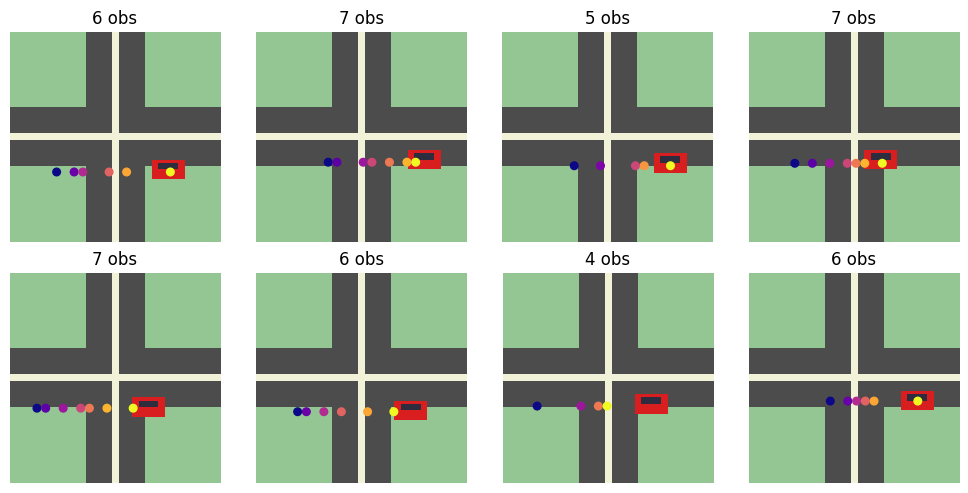

In [ ]:

N_TRAIN_TRAJ = 40
N_TEST_TRAJ = 6
DENSE_STEPS = 14
SPARSE_MIN = 4
SPARSE_MAX = 7


def make_dataset(n_traj, seed_offset=0):
    rng = np.random.default_rng(SEED + seed_offset)
    dense_t = np.linspace(0.0, T_END, DENSE_STEPS, dtype=np.float32)

    trajs = []
    all_images = []
    all_positions = []

    for _ in range(n_traj):
        x0 = rng.uniform(0.08, 0.30)
        y0 = rng.uniform(0.57, 0.68)  # slightly different horizontal lanes

        dense_pos = np.stack([car_position(x0, y0, float(t)) for t in dense_t])
        dense_img = np.stack([render_numpy(p) for p in dense_pos])

        k = rng.integers(SPARSE_MIN, SPARSE_MAX + 1)
        sparse_idx = np.sort(rng.choice(DENSE_STEPS, size=k, replace=False))
        sparse_t = dense_t[sparse_idx]
        sparse_pos = dense_pos[sparse_idx]
        sparse_img = dense_img[sparse_idx]

        trajs.append({
            'x0': np.array([x0, y0], dtype=np.float32),
            'dense_t': dense_t,
            'dense_pos': dense_pos,
            'dense_img': dense_img,
            'sparse_t': sparse_t,
            'sparse_pos': sparse_pos,
            'sparse_img': sparse_img,
            'sparse_idx': sparse_idx,
        })

        all_images.append(dense_img)
        all_positions.append(dense_pos)

    all_images = np.concatenate(all_images, axis=0)
    all_positions = np.concatenate(all_positions, axis=0)
    return trajs, all_images, all_positions


train_trajs, train_imgs_np, train_pos_np = make_dataset(N_TRAIN_TRAJ, seed_offset=0)
test_trajs,  test_imgs_np,  test_pos_np  = make_dataset(N_TEST_TRAJ, seed_offset=100)

print('Train frame bank:', train_imgs_np.shape)
print('Train positions :', train_pos_np.shape)

# Show a few sparse observation patterns.
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, traj in zip(axes.flat, train_trajs[:8]):
    ax.imshow(traj['dense_img'][-1])
    ax.scatter((traj['sparse_pos'][:, 0] * (W - 1)), (traj['sparse_pos'][:, 1] * (H - 1)),
               c=np.linspace(0, 1, len(traj['sparse_pos'])), cmap='plasma', s=30)
    ax.set_title(f"{len(traj['sparse_t'])} obs")
    ax.axis('off')
plt.tight_layout()
plt.show()



## 3. Structured encoder and decoder

### Encoder
The encoder is a CNN that maps the input image to **two numbers**:

$$
\text{Encoder}(I) = (\hat{x}, \hat{y} ).
$$

We use a final sigmoid so the prediction naturally lies in $[0,1]$.

### Decoder / renderer
The decoder is not a generic deconvolutional network.
Instead, it is a **structured renderer**:

- it knows the static background,
- it knows the car size and appearance,
- given $(x,y)$, it draws a soft rectangle at that location.

This is a much easier inverse problem, and the latent space has a direct physical meaning.


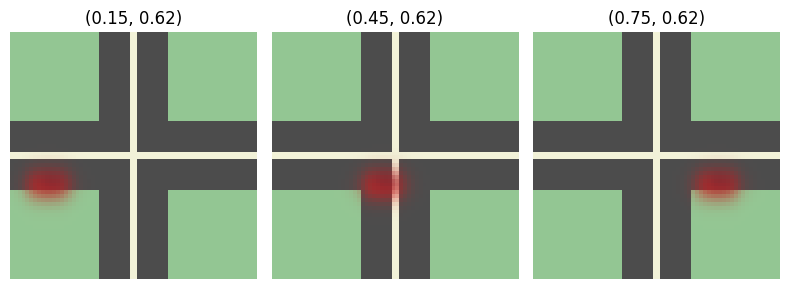

In [ ]:

background_t = torch.tensor(BACKGROUND.transpose(2, 0, 1), dtype=torch.float32, device=DEVICE)


class PositionEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=5, stride=2, padding=2),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=5, stride=2, padding=2),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 64),
            nn.ReLU(),
            nn.Linear(64, 2),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.net(x)


class RendererDecoder(nn.Module):
    """Differentiable renderer from latent position (x,y) to image.

    The image is formed as:
        image = background * (1 - mask) + car_color * mask
    plus a small dark window strip.
    """
    def __init__(self, height=H, width=W, car_w=CAR_W, car_h=CAR_H, temperature=1.3):
        super().__init__()
        self.height = height
        self.width = width
        self.car_w = float(car_w)
        self.car_h = float(car_h)
        self.temperature = float(temperature)

        ys = torch.arange(height, dtype=torch.float32)
        xs = torch.arange(width, dtype=torch.float32)
        yy, xx = torch.meshgrid(ys, xs, indexing='ij')
        self.register_buffer('xx', xx[None, None, :, :])
        self.register_buffer('yy', yy[None, None, :, :])
        self.register_buffer('background', background_t[None, :, :, :])

        self.register_buffer('body_color', torch.tensor([0.85, 0.12, 0.12], dtype=torch.float32)[None, :, None, None])
        self.register_buffer('window_color', torch.tensor([0.18, 0.18, 0.25], dtype=torch.float32)[None, :, None, None])

    def soft_box(self, cx, cy, box_w, box_h):
        # cx, cy have shape [B,1,1,1] in pixel coordinates.
        left   = torch.sigmoid((self.xx - (cx - box_w / 2.0)) / self.temperature)
        right  = torch.sigmoid((self.xx - (cx + box_w / 2.0)) / self.temperature)
        top    = torch.sigmoid((self.yy - (cy - box_h / 2.0)) / self.temperature)
        bottom = torch.sigmoid((self.yy - (cy + box_h / 2.0)) / self.temperature)

        mask_x = left - right
        mask_y = top - bottom
        return mask_x * mask_y

    def forward(self, pos):
        # pos shape [B,2] in normalized [0,1] coordinates.
        cx = pos[:, 0].view(-1, 1, 1, 1) * (self.width - 1)
        cy = pos[:, 1].view(-1, 1, 1, 1) * (self.height - 1)

        body_mask = self.soft_box(cx, cy, self.car_w, self.car_h)

        # Slightly smaller window strip shifted upward.
        win_cy = cy - 0.8
        win_cx = cx + 0.6
        window_mask = self.soft_box(win_cx, win_cy, self.car_w * 0.55, self.car_h * 0.35)

        bg = self.background.repeat(pos.shape[0], 1, 1, 1)
        img = bg * (1.0 - body_mask) + self.body_color.repeat(pos.shape[0], 1, 1, 1) * body_mask
        img = img * (1.0 - window_mask) + self.window_color.repeat(pos.shape[0], 1, 1, 1) * window_mask
        return img.clamp(0.0, 1.0)


encoder = PositionEncoder().to(DEVICE)
decoder = RendererDecoder().to(DEVICE)

# Sanity check: decoding known positions.
with torch.no_grad():
    test_pos = torch.tensor([[0.15, 0.62], [0.45, 0.62], [0.75, 0.62]], dtype=torch.float32, device=DEVICE)
    rendered = decoder(test_pos).cpu().numpy().transpose(0, 2, 3, 1)

fig, axes = plt.subplots(1, 3, figsize=(8, 3))
for ax, img, p in zip(axes, rendered, test_pos.cpu().numpy()):
    ax.imshow(img)
    ax.set_title(f'({p[0]:.2f}, {p[1]:.2f})')
    ax.axis('off')
plt.tight_layout()
plt.show()



## 4. Train the encoder using reconstruction + coordinate supervision

Because our data are synthetic, we know the true car center. That is very convenient for teaching.

We train the encoder with two terms:

$$
 L = L_{\text{recon}} + \lambda\, L_{\text{coord}}.
$$

- **Reconstruction loss**: the predicted position is decoded back into an image and compared to the true image.
- **Coordinate loss**: the predicted $(x,y)$ is also compared directly to the true car center.

This encourages the encoder to learn a physically meaningful latent representation.


step  200 | total=0.00113 | recon=0.00087 | coord=0.00003
step  400 | total=0.00120 | recon=0.00089 | coord=0.00003
step  600 | total=0.00112 | recon=0.00089 | coord=0.00002
step  800 | total=0.00108 | recon=0.00088 | coord=0.00002


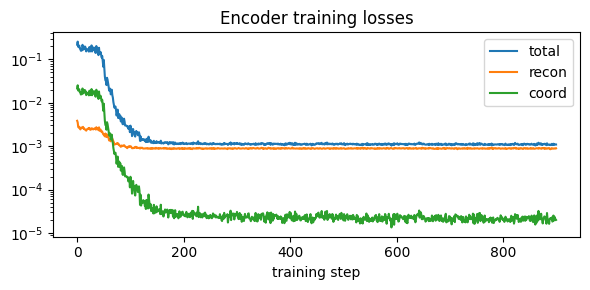

In [ ]:

train_imgs = torch.tensor(train_imgs_np.transpose(0, 3, 1, 2), dtype=torch.float32, device=DEVICE)
train_pos = torch.tensor(train_pos_np, dtype=torch.float32, device=DEVICE)

def sample_batch(batch_size=64):
    idx = torch.randint(0, train_imgs.shape[0], (batch_size,), device=DEVICE)
    return train_imgs[idx], train_pos[idx]

optimizer_enc = torch.optim.Adam(encoder.parameters(), lr=1e-3)
coord_weight = 10.0
n_steps = 900
history = []

encoder.train()
for step in range(1, n_steps + 1):
    img_b, pos_b = sample_batch(64)
    pred_pos = encoder(img_b)
    recon = decoder(pred_pos)

    recon_loss = F.mse_loss(recon, img_b)
    coord_loss = F.mse_loss(pred_pos, pos_b)
    loss = recon_loss + coord_weight * coord_loss

    optimizer_enc.zero_grad()
    loss.backward()
    optimizer_enc.step()

    history.append([loss.item(), recon_loss.item(), coord_loss.item()])

    if step % 200 == 0:
        print(f"step {step:4d} | total={loss.item():.5f} | recon={recon_loss.item():.5f} | coord={coord_loss.item():.5f}")

history = np.asarray(history)
plt.figure(figsize=(6, 3))
plt.plot(history[:, 0], label='total')
plt.plot(history[:, 1], label='recon')
plt.plot(history[:, 2], label='coord')
plt.yscale('log')
plt.xlabel('training step')
plt.title('Encoder training losses')
plt.legend()
plt.tight_layout()
plt.show()


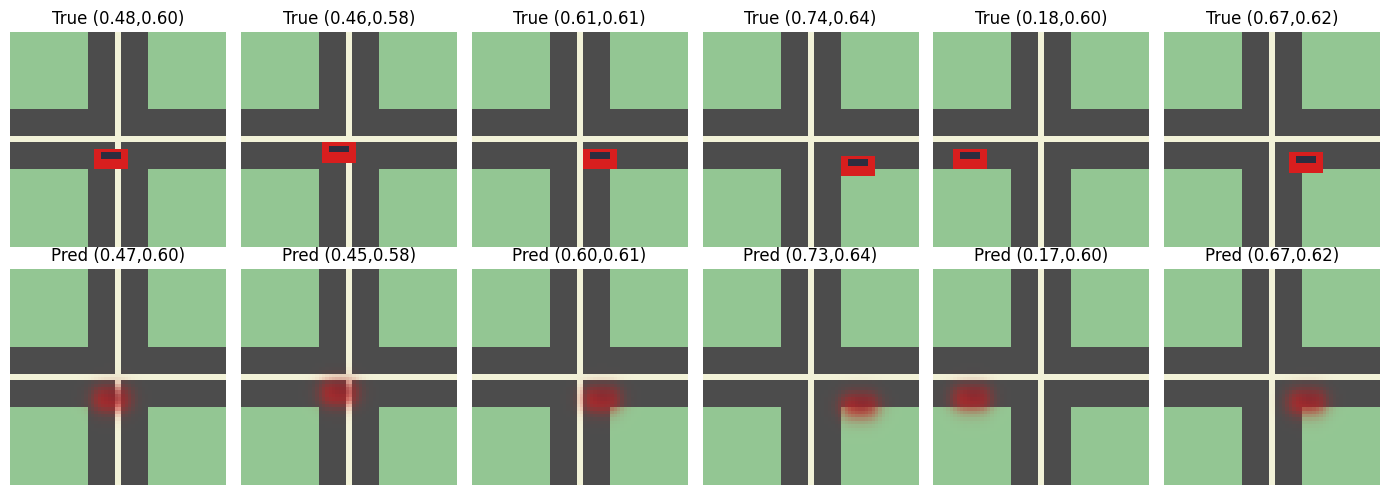

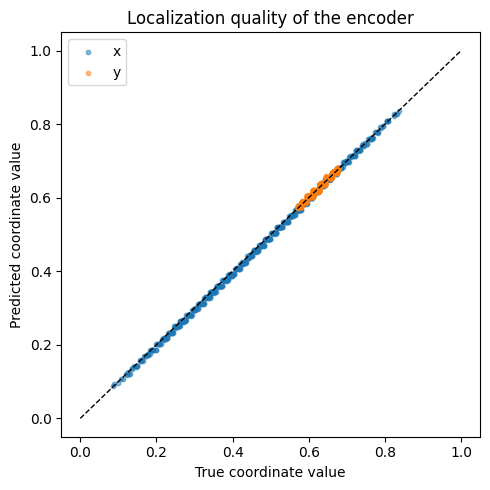

In [ ]:

# Evaluate reconstruction and localization on a few examples.
encoder.eval()
with torch.no_grad():
    idx = torch.randperm(train_imgs.shape[0], device=DEVICE)[:6]
    imgs = train_imgs[idx]
    true_pos = train_pos[idx]
    pred_pos = encoder(imgs)
    recon = decoder(pred_pos)

imgs_np = imgs.cpu().numpy().transpose(0, 2, 3, 1)
recon_np = recon.cpu().numpy().transpose(0, 2, 3, 1)
true_pos_np = true_pos.cpu().numpy()
pred_pos_np = pred_pos.cpu().numpy()

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for i in range(6):
    axes[0, i].imshow(imgs_np[i])
    axes[0, i].set_title(f"True ({true_pos_np[i,0]:.2f},{true_pos_np[i,1]:.2f})")
    axes[0, i].axis('off')

    axes[1, i].imshow(recon_np[i])
    axes[1, i].set_title(f"Pred ({pred_pos_np[i,0]:.2f},{pred_pos_np[i,1]:.2f})")
    axes[1, i].axis('off')

axes[0, 0].set_ylabel('Original', fontsize=11)
axes[1, 0].set_ylabel('Decoded from encoder', fontsize=11)
plt.tight_layout()
plt.show()

# Scatter plot: true position vs encoded position.
with torch.no_grad():
    pred_train_pos = encoder(train_imgs).cpu().numpy()

plt.figure(figsize=(5, 5))
plt.scatter(train_pos_np[:, 0], pred_train_pos[:, 0], s=10, alpha=0.5, label='x')
plt.scatter(train_pos_np[:, 1], pred_train_pos[:, 1], s=10, alpha=0.5, label='y')
lims = [0, 1]
plt.plot(lims, lims, 'k--', linewidth=1)
plt.xlabel('True coordinate value')
plt.ylabel('Predicted coordinate value')
plt.title('Localization quality of the encoder')
plt.legend()
plt.tight_layout()
plt.show()



## 5. Learn a Neural ODE in latent position space

Now that images can be encoded into positions, we solve the temporal problem.

For each trajectory we only use **sparse irregular observations**:

$$
(z(t_0), z(t_1), \dots, z(t_k)).
$$

We train a Neural ODE to fit a continuous latent trajectory:

$$
\dot z = f_\theta(z).
$$

This example is intentionally simple: the latent state is already interpretable and low-dimensional.
So the main learning task becomes learning the dynamics itself.


epoch  250 | latent fit loss = 0.000024
epoch  500 | latent fit loss = 0.000021
epoch  750 | latent fit loss = 0.000017
epoch 1000 | latent fit loss = 0.000020


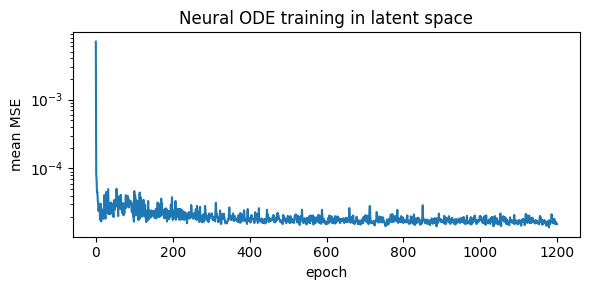

In [ ]:

class ODEFunc(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, 2),
        )

    def forward(self, t, z):
        return self.net(z)




ode_func = ODEFunc().to(DEVICE)
optimizer_ode = torch.optim.Adam(ode_func.parameters(), lr=1e-3)

# Encode the sparse observations once (we keep the encoder frozen here).
encoder.eval()
encoded_train_sequences = []
with torch.no_grad():
    for traj in train_trajs:
        imgs = torch.tensor(traj['sparse_img'].transpose(0, 3, 1, 2), dtype=torch.float32, device=DEVICE)
        z_obs = encoder(imgs)
        encoded_train_sequences.append({
            't': torch.tensor(traj['sparse_t'], dtype=torch.float32, device=DEVICE),
            'z_obs': z_obs,
            'z_true': torch.tensor(traj['sparse_pos'], dtype=torch.float32, device=DEVICE),
        })


ode_history = []
for epoch in range(1, 1201):
    losses = []
    random.shuffle(encoded_train_sequences)

    for seq in encoded_train_sequences:
        t_obs = seq['t']
        z_obs = seq['z_obs']

        pred = odeint(ode_func, z_obs[0], t_obs, method="dopri5")
        loss = F.mse_loss(pred, z_obs)

        optimizer_ode.zero_grad()
        loss.backward()
        optimizer_ode.step()
        losses.append(loss.item())

    mean_loss = float(np.mean(losses))
    ode_history.append(mean_loss)
    if epoch % 250 == 0:
        print(f"epoch {epoch:4d} | latent fit loss = {mean_loss:.6f}")

plt.figure(figsize=(6, 3))
plt.plot(ode_history)
plt.yscale('log')
plt.xlabel('epoch')
plt.ylabel('mean MSE')
plt.title('Neural ODE training in latent space')
plt.tight_layout()
plt.show()



## 6. Decode the learned latent trajectory back to images

This is the full pipeline:

$$
I(t_0) \xrightarrow{\text{encoder}} z(t_0)
\xrightarrow{\text{Neural ODE}} z(t)
\xrightarrow{\text{decoder}} \hat I(t).
$$

We compare:

- the ground-truth trajectory,
- the encoded observations,
- the Neural ODE prediction on a dense time grid,
- the reconstructed images at intermediate times.


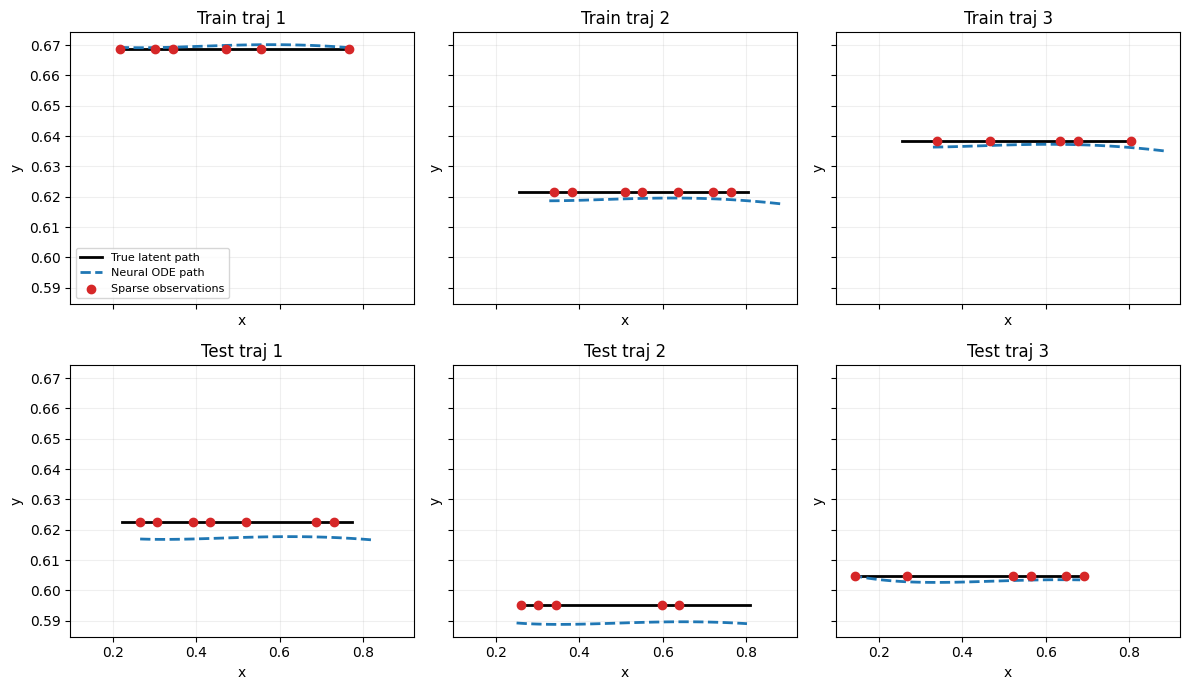

In [ ]:

def predict_dense_from_first_image(traj, n_dense=60):
    encoder.eval()
    ode_func.eval()
    t_dense = torch.linspace(0.0, T_END, n_dense, device=DEVICE)

    first_img = torch.tensor(traj['sparse_img'][0].transpose(2, 0, 1)[None], dtype=torch.float32, device=DEVICE)
    with torch.no_grad():
        z0 = encoder(first_img)[0]
        z_dense = odeint(ode_func, z0, t_dense, method="dopri5")
        imgs_dense = decoder(z_dense)

    return t_dense.cpu().numpy(), z_dense.cpu().numpy(), imgs_dense.cpu().numpy().transpose(0, 2, 3, 1)


# Latent-space comparison for a few trajectories.
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
for row, source in enumerate([train_trajs[:3], test_trajs[:3]]):
    for col, traj in enumerate(source):
        ax = axes[row, col]
        t_dense, z_pred, _ = predict_dense_from_first_image(traj, n_dense=80)
        true_dense = traj['dense_pos']
        sparse = traj['sparse_pos']

        ax.plot(true_dense[:, 0], true_dense[:, 1], color='black', linewidth=2, label='True latent path')
        ax.plot(z_pred[:, 0], z_pred[:, 1], '--', linewidth=2, label='Neural ODE path')
        ax.scatter(sparse[:, 0], sparse[:, 1], color='tab:red', zorder=5, label='Sparse observations')
        ax.set_title(('Train' if row == 0 else 'Test') + f' traj {col+1}')
        ax.set_xlabel('x')
        ax.set_ylabel('y')
        ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()


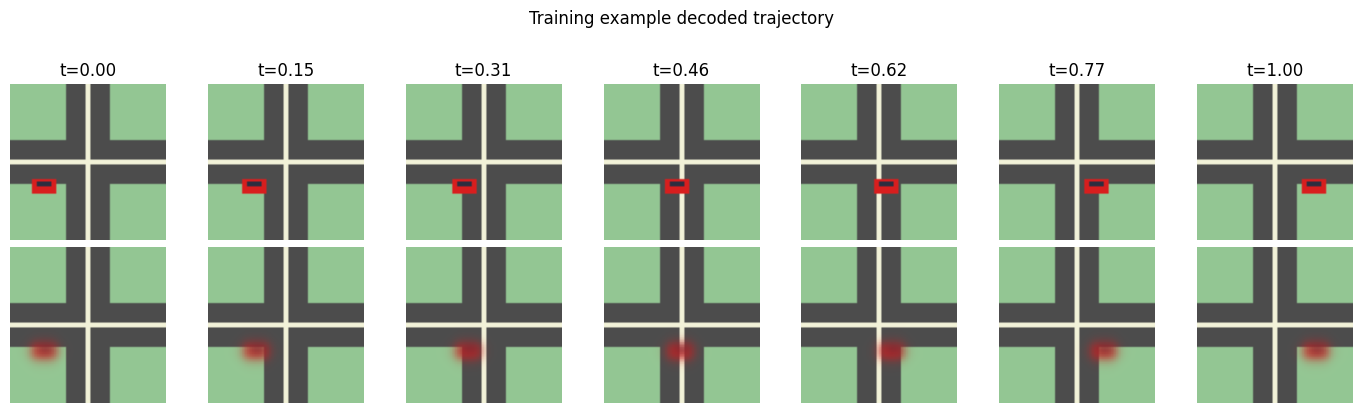

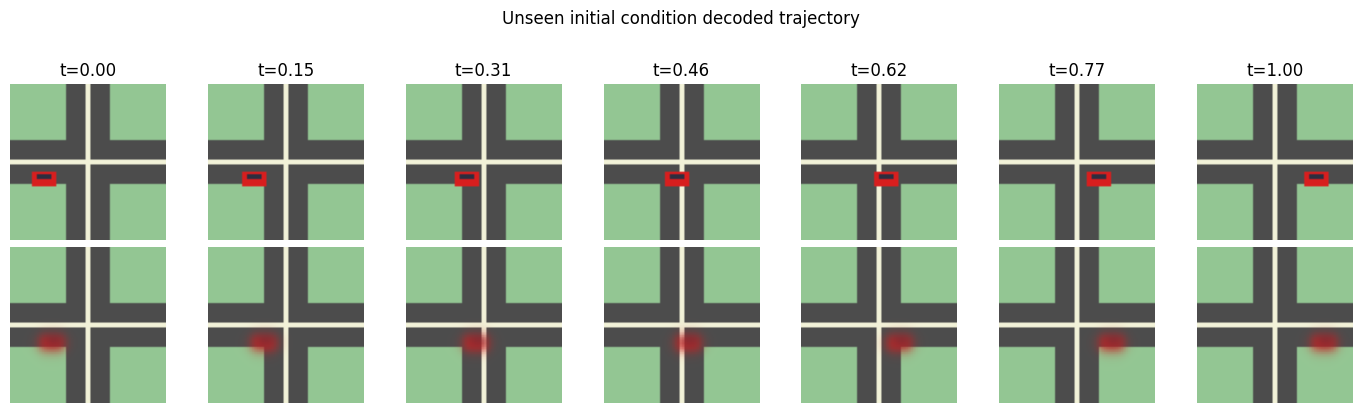

In [ ]:

# Show decoded image sequences.
def show_sequence(traj, title_prefix=''):
    t_dense, z_pred, imgs_pred = predict_dense_from_first_image(traj, n_dense=7)
    idx = np.linspace(0, len(traj['dense_t']) - 1, 7).astype(int)
    true_imgs = traj['dense_img'][idx]

    fig, axes = plt.subplots(2, 7, figsize=(14, 4))
    for j in range(7):
        axes[0, j].imshow(true_imgs[j])
        axes[0, j].set_title(f't={traj["dense_t"][idx[j]]:.2f}')
        axes[0, j].axis('off')

        axes[1, j].imshow(imgs_pred[j])
        axes[1, j].axis('off')

    axes[0, 0].set_ylabel('Ground truth', fontsize=11)
    axes[1, 0].set_ylabel('Predicted', fontsize=11)
    plt.suptitle(title_prefix + ' decoded trajectory', y=1.02)
    plt.tight_layout()
    plt.show()

show_sequence(train_trajs[0], 'Training example')
show_sequence(test_trajs[0], 'Unseen initial condition')


### Natural extensions

If you want a more advanced version later, possible next steps are:

- allow **different speeds**, and then extend the latent state to $(x,y,v_x,v_y)$,
- handle **turning at the intersection**,
- use **keypoint-based encoders** or a **spatial broadcast decoder**,
- train the whole model **end-to-end** instead of freezing the encoder before learning the ODE.
